In [66]:
import seaborn as sns

In [69]:
import numpy as np

In [71]:
import matplotlib.pyplot as plt

In [67]:
import pandas as pd

In [68]:


df = pd.read_csv('/content/air_quality_dataset.csv')

df.head()

,PM2.5,PM10,NOx,NO2,SO2,VOCs,CO,CO2,CH4,Temperature
0,39.967142,57.926035,116.192213,55.230299,4.531693,75.317261,2.789606,427.674347,1.706105,31.085120
1,101.935672,150.774299,76.826826,79.051618,18.744780,145.083987,1.966569,529.739619,2.492663,33.711103
2,70.996192,138.948796,158.731020,60.466604,14.892239,145.147338,2.626446,499.889443,2.431165,33.778698
3,28.464728,63.643900,25.385343,15.333286,7.647429,130.022319,1.779360,388.283712,1.818563,31.565877
4,78.265276,113.977926,105.644340,59.202337,17.696806,181.713667,3.240533,464.739197,2.597225,32.229835


In [2]:
df.info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 500 entries, 0 to 499
Data columns (total 10 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PM2.5        500 non-null    float64
 1   PM10         500 non-null    float64
 2   NOx          500 non-null    float64
 3   NO2          500 non-null    float64
 4   SO2          500 non-null    float64
 5   VOCs         500 non-null    float64
 6   CO           500 non-null    float64
 7   CO2          500 non-null    float64
 8   CH4          500 non-null    float64
 9   Temperature  500 non-null    float64
dtypes: float64(10)
memory usage: 39.2 KB


In [3]:
df.describe()


,PM2.5,PM10,NOx,NO2,SO2,VOCs,CO,CO2,CH4,Temperature
count,500.000000,500.000000,500.000000,500.000000,500.000000,500.000000,500.000000,500.000000,500.000000,500.000000
mean,54.671620,84.703251,91.814080,42.410820,11.504816,112.193098,2.177705,439.288087,2.130439,30.448413
std,22.799473,30.567912,54.808414,26.343669,7.306978,39.471686,0.824762,51.220578,0.391396,2.957290
min,10.757597,12.932337,-0.076323,-1.942140,-1.095555,27.555617,0.366992,366.063158,1.388407,19.581349
25%,36.372940,61.118607,35.457263,17.448632,5.976492,81.516729,1.536915,397.399610,1.837395,28.481974
50%,48.038599,78.135558,95.452284,39.211583,8.681222,104.819124,2.045519,420.934319,2.066709,30.432756
75%,73.820566,110.270086,134.709240,63.817763,17.116673,140.588100,2.726020,490.968315,2.386267,32.614954
max,127.616632,171.594187,225.886935,115.916428,31.941860,231.926017,4.798935,558.924256,3.352266,39.778713


In [4]:
df.isnull().sum()

,0
PM2.5,0
PM10,0
NOx,0
NO2,0
SO2,0
VOCs,0
CO,0
CO2,0
CH4,0
Temperature,0


In [70]:


df.loc[2, 'PM2.5'] = np.nan
df.loc[5, 'NOx'] = np.nan
df.loc[10, 'Temperature'] = np.nan

In [6]:
df.isnull().sum()

,0
PM2.5,1
PM10,0
NOx,1
NO2,0
SO2,0
VOCs,0
CO,0
CO2,0
CH4,0
Temperature,1


In [65]:
df.isnull().sum()

,0
PM2.5,0
PM10,0
NOx,0
NO2,0
SO2,0
VOCs,0
CO,0
CO2,0
CH4,0
Temperature,0


In [11]:
df['AQI_Score'] = (
    df['PM2.5'] +
    df['PM10'] +
    df['NOx']
) / 3

In [12]:
df[['PM2.5','PM10','NOx','AQI_Score']].head()

,PM2.5,PM10,NOx,AQI_Score
0,39.967142,57.926035,116.192213,71.361797
1,101.935672,150.774299,76.826826,109.845599
2,54.638905,138.948796,158.731020,117.439574
3,28.464728,63.643900,25.385343,39.164657
4,78.265276,113.977926,105.644340,99.295847


In [14]:
df[['AQI_Score','Air_Quality']].head()

,AQI_Score,Air_Quality
0,71.361797,Moderate
1,109.845599,Poor
2,117.439574,Poor
3,39.164657,Good
4,99.295847,Moderate


In [60]:
print(df.loc[2])

PM2.5           54.638905
PM10           138.948796
NOx             158.73102
NO2             60.466604
SO2             14.892239
VOCs           145.147338
CO               2.626446
CO2            499.889443
CH4              2.431165
Temperature     33.778698
AQI_Score      117.439574
Air_Quality          Poor
Name: 2, dtype: object


In [20]:
print(df.loc[5])

PM2.5           16.243232
PM10            39.498268
NOx             95.381901
NO2             30.932793
SO2              5.952085
VOCs           106.073225
CO               2.105794
CO2            425.970446
CH4              1.620733
Temperature     29.776024
AQI_Score       50.374467
Air_Quality      Moderate
Name: 5, dtype: object


In [21]:
df['Temperature'] = df['Temperature'].fillna(
    df['Temperature'].mode()[0]
)

In [22]:
print(df.loc[10])

PM2.5           67.634231
PM10            73.142401
NOx             32.575504
NO2              14.62777
SO2              4.162458
VOCs            99.337153
CO               1.524092
CO2            414.632421
CH4              1.961528
Temperature     19.581349
AQI_Score       57.784045
Air_Quality      Moderate
Name: 10, dtype: object


In [23]:
print("Mean PM2.5 =", df['PM2.5'].mean())
print("Median NOx =", df['NOx'].median())
print("Mode Temperature =", df['Temperature'].mode()[0])

Mean PM2.5 = 54.63890540769539
Median NOx = 95.38190098
Mode Temperature = 19.58134867


In [24]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 500 entries, 0 to 499
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PM2.5        500 non-null    float64
 1   PM10         500 non-null    float64
 2   NOx          500 non-null    float64
 3   NO2          500 non-null    float64
 4   SO2          500 non-null    float64
 5   VOCs         500 non-null    float64
 6   CO           500 non-null    float64
 7   CO2          500 non-null    float64
 8   CH4          500 non-null    float64
 9   Temperature  500 non-null    float64
 10  AQI_Score    500 non-null    float64
 11  Air_Quality  500 non-null    object 
dtypes: float64(11), object(1)
memory usage: 47.0+ KB


In [25]:
df.describe()

,PM2.5,PM10,NOx,NO2,SO2,VOCs,CO,CO2,CH4,Temperature,AQI_Score
count,500.000000,500.000000,500.000000,500.000000,500.000000,500.000000,500.000000,500.000000,500.000000,500.000000,500.000000
mean,54.638905,84.703251,91.773028,42.410820,11.504816,112.193098,2.177705,439.288087,2.130439,30.429767,77.038395
std,22.787735,30.567912,54.798018,26.343669,7.306978,39.471686,0.824762,51.220578,0.391396,2.996181,30.512038
min,10.757597,12.932337,-0.076323,-1.942140,-1.095555,27.555617,0.366992,366.063158,1.388407,19.581349,27.237645
25%,36.372940,61.118607,35.457263,17.448632,5.976492,81.516729,1.536915,397.399610,1.837395,28.446909,51.794091
50%,48.038599,78.135558,95.381901,39.211583,8.681222,104.819124,2.045519,420.934319,2.066709,30.432756,64.580971
75%,73.820566,110.270086,134.709240,63.817763,17.116673,140.588100,2.726020,490.968315,2.386267,32.614954,108.170219
max,127.616632,171.594187,225.886935,115.916428,31.941860,231.926017,4.798935,558.924256,3.352266,39.778713,142.438950


In [26]:
df.isnull().sum()

,0
PM2.5,0
PM10,0
NOx,0
NO2,0
SO2,0
VOCs,0
CO,0
CO2,0
CH4,0
Temperature,0


In [61]:
print("Mean of PM2.5 =", df['PM2.5'].mean())

Mean of PM2.5 = 54.63890540769539


In [32]:
print("Median of NOx =", df['NOx'].median())

Median of NOx = 95.38190098


In [33]:
df['Temperature'] = df['Temperature'].fillna(
    df['Temperature'].mode()[0]
)

In [34]:
print("Mode of Temperature =", df['Temperature'].mode()[0])


Mode of Temperature = 19.58134867


In [35]:
df.isnull().sum()

,0
PM2.5,0
PM10,0
NOx,0
NO2,0
SO2,0
VOCs,0
CO,0
CO2,0
CH4,0
Temperature,0


In [64]:
df[['PM2.5', 'PM10', 'NOx', 'AQI_Score']].head()

,PM2.5,PM10,NOx,AQI_Score
0,39.967142,57.926035,116.192213,71.361797
1,101.935672,150.774299,76.826826,109.845599
2,54.638905,138.948796,158.731020,117.439574
3,28.464728,63.643900,25.385343,39.164657
4,78.265276,113.977926,105.644340,99.295847


In [62]:
def category(aqi):
    if aqi < 50:
        return "Good"
    elif aqi < 100:
        return "Moderate"
    else:
        return "Poor"


In [39]:
df['Air_Quality'] = df['AQI_Score'].apply(category)

In [40]:
df[['AQI_Score', 'Air_Quality']].head()

,AQI_Score,Air_Quality
0,71.361797,Moderate
1,109.845599,Poor
2,117.439574,Poor
3,39.164657,Good
4,99.295847,Moderate


In [41]:
df['Air_Quality'].value_counts()

,count
Air_Quality,
Moderate,236
Poor,158
Good,106


In [42]:
df[['PM2.5', 'PM10', 'NOx', 'NO2', 'SO2']].mean()

,0
PM2.5,54.638905
PM10,84.703251
NOx,91.773028
NO2,42.410820
SO2,11.504816


In [43]:
df['AQI_Score'].max()


142.4389495

In [44]:
df['AQI_Score'].min()

27.237645167333337

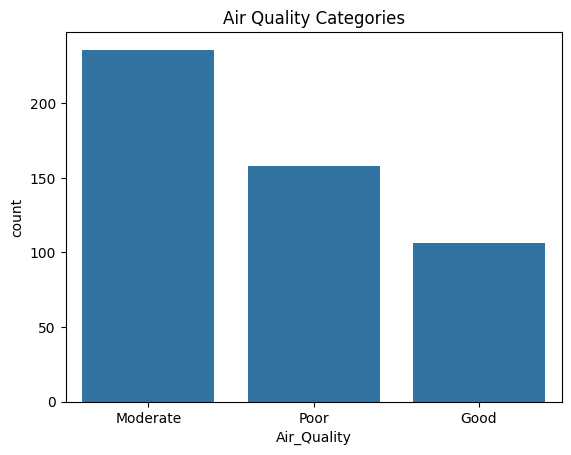

In [47]:
sns.countplot(
    x='Air_Quality',
    data=df
)

plt.title("Air Quality Categories")
plt.show()

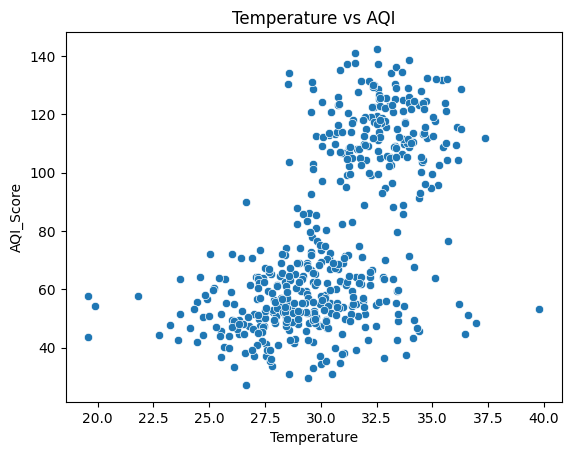

In [48]:
sns.scatterplot(
    x='Temperature',
    y='AQI_Score',
    data=df
)

plt.title("Temperature vs AQI")
plt.show()

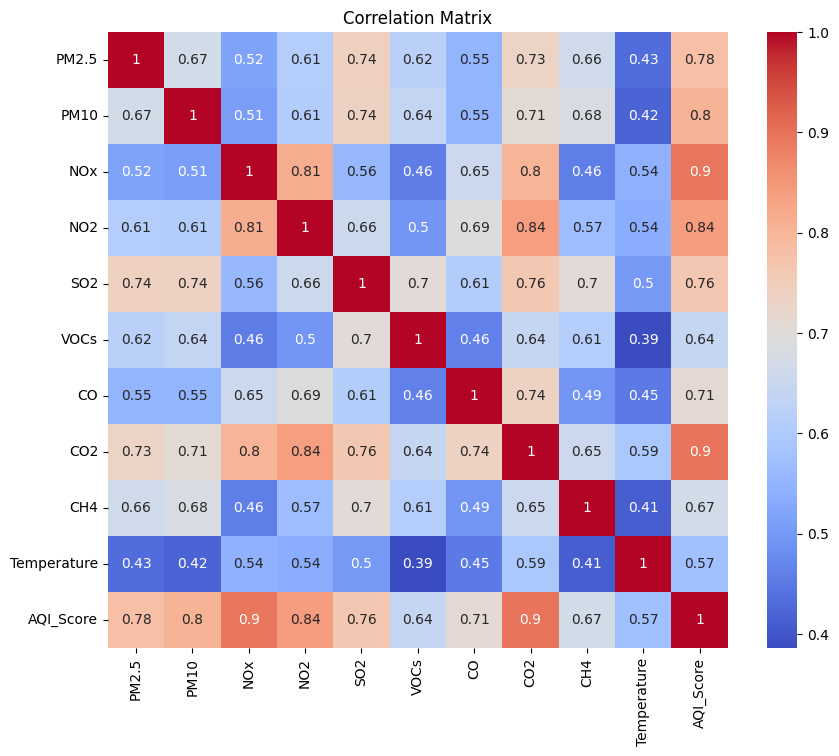

In [49]:
plt.figure(figsize=(10,8))

sns.heatmap(
    df.corr(numeric_only=True),
    annot=True,
    cmap='coolwarm'
)

plt.title("Correlation Matrix")
plt.show()

In [50]:
df[['AQI_Score','Air_Quality']].head()

,AQI_Score,Air_Quality
0,71.361797,Moderate
1,109.845599,Poor
2,117.439574,Poor
3,39.164657,Good
4,99.295847,Moderate


Observation:
The dataset contains Good, Moderate, and Poor air quality categories.
Poor and Moderate categories appear more frequently than Good category.

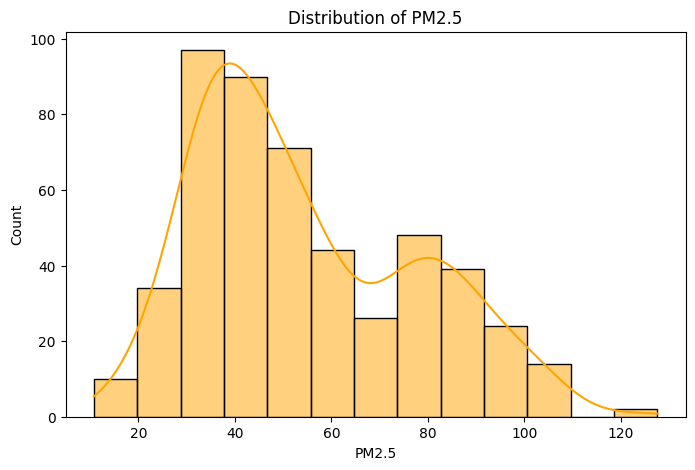

In [72]:


plt.figure(figsize=(8,5))

sns.histplot(
    df['PM2.5'],
    kde=True,
    color='orange'
)

plt.title('Distribution of PM2.5')
plt.show()

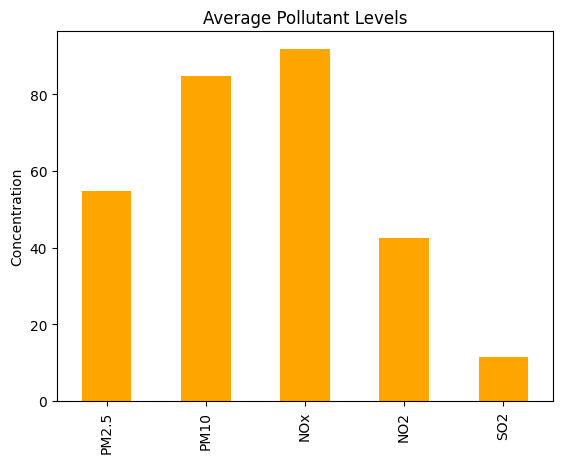

In [55]:
avg_pollutants = df[
    ['PM2.5','PM10','NOx','NO2','SO2']
].mean()

avg_pollutants.plot(
    kind='bar',
    color='orange'
)

plt.title('Average Pollutant Levels')
plt.ylabel('Concentration')
plt.show()

In [56]:
df['Air_Quality'].value_counts()

,count
Air_Quality,
Moderate,236
Poor,158
Good,106


In [57]:
print("Highest AQI:", df['AQI_Score'].max())

Highest AQI: 142.4389495


In [58]:
print("Lowest AQI:", df['AQI_Score'].min())

Lowest AQI: 27.237645167333337


In [59]:
df[['PM2.5','PM10','NOx','NO2','SO2']].mean()

,0
PM2.5,54.638905
PM10,84.703251
NOx,91.773028
NO2,42.410820
SO2,11.504816


Conclusion

The air quality dataset was analyzed using Pandas, NumPy, Matplotlib, and Seaborn. Missing values were handled using mean, median, and mode imputation techniques. Data transformation was performed by creating AQI_Score and Air_Quality features. Insights were generated from pollutant concentrations and air quality categories. Various visualizations such as histogram, bar chart, count plot, scatter plot, and heatmap were used to analyze patterns and relationships in the dataset.